# 06 · My Dashboard

## 🎯 Question
*What question does this dashboard answer, and for whom?*

How did the scale of the trans-Atlantic slave trade to the Americas change between 1520 and 1866,
and who carried it out, from where, and to where? Built for history students and general readers
who want to explore the voyage records interactively. *(Draft — edit in my own words.)*

## 📊 Dataset
- **Source:** Trans-Atlantic Slave Trade Database ([SlaveVoyages.org](https://www.slavevoyages.org/)), course copy in `Proctor-F26-Data-and-History/data/Trans-Atlantic-Slave-Trade_Americas.csv`
- **Format / size:** CSV, 20,741 voyages (one row per voyage), 14 columns, ~12.6 MB
- **Key columns:** `year_of_arrival`, `flag`, `place_of_purchase`, `place_of_landing`, `total_embarked`, `total_disembarked`, `percent_women` / `percent_children` / `percent_men`, `resistance_label`
- **Limitations:** women/children/men percentages exist for only ~14% of voyages; resistance is recorded for only ~2%; 6% of voyages have no flag; many places are "port unspecified"; the data counts people as cargo figures recorded by slavers.

## 🗺️ Dashboard plan
- **Charts:** 1 line chart (people embarked vs. disembarked per year); 2 donut pie charts (top 10 + "Others")
- **Interactive controls:** a year range slider that filters all three charts; a dropdown above each pie chart to pick its variable (flag, place of purchase, place of landing, women/children/men, resistance)

## Load the data

In [42]:
import pandas as pd

raw = pd.read_csv("../../Proctor-F26-Data-and-History/data/Trans-Atlantic-Slave-Trade_Americas.csv")
print(raw.shape)   # (voyages, columns)
raw.head()

(20741, 14)


,year_of_arrival,flag,place_of_purchase,place_of_landing,percent_women,percent_children,percent_men,total_embarked,total_disembarked,resistance_label,vessel_name,captain's_name,voyage_id,sources
0,1520,NaN,Portuguese Guinea,San Juan,NaN,NaN,NaN,324.0,259.0,NaN,,NaN,42987,"[u'AGI,Patronato 175, r.9<><p><em>AG!</em> (Se..."
1,1525,Portugal / Brazil,Sao Tome,"Hispaniola, unspecified",NaN,NaN,NaN,359.0,287.0,NaN,S Maria de Bogoña,"Monteiro, Pero",46473,"[u'ANTT,CC,Parte II, maco 131, doc 54<><i>Inst..."
2,1526,Spain / Uruguay,Cape Verde Islands,"Cuba, port unspecified",NaN,NaN,NaN,359.0,287.0,NaN,,"Carega, Esteban (?)",11297,"[u'Pike,60-1,172<>Pike, Ruth, <i>Enterprise</i..."
3,1526,Spain / Uruguay,Cape Verde Islands,"Cuba, port unspecified",NaN,NaN,NaN,359.0,287.0,NaN,,"Carega, Esteban (?)",11298,"[u'Pike,60-1,172<>Pike, Ruth, <i>Enterprise</i..."
4,1526,NaN,Cape Verde Islands,Caribbean (colony unspecified),NaN,NaN,NaN,359.0,287.0,NaN,S Anton,"Leon, Juan de",42631,"[u'Chaunus, 3: 162-63<><p>Chaunus, <em>xxxxxx<..."


In [43]:
# How complete is each column? (share of voyages with a missing value)
raw.isna().mean().round(2)

year_of_arrival      0.00
flag                 0.06
place_of_purchase    0.00
place_of_landing     0.00
percent_women        0.86
percent_children     0.86
percent_men          0.86
total_embarked       0.00
total_disembarked    0.00
resistance_label     0.98
vessel_name          0.00
captain's_name       0.06
voyage_id            0.00
sources              0.00
dtype: float64

### 📝 My notes
- There are a lot of empty columns. Will have to be careful that null values do not mess with what we are trying to do. Create specific conditions for graphs if there are empty values. 

## Clean the data

In [44]:
# Keep only the columns the dashboard uses, and label missing flags
columns = ['year_of_arrival', 'flag', 'place_of_purchase', 'place_of_landing',
           'total_embarked', 'total_disembarked',
           'percent_women', 'percent_children', 'percent_men', 'resistance_label']
voyages = raw[columns].copy()
voyages['flag'] = voyages['flag'].fillna('Unknown')

# Save a smaller copy next to the app so Render can find it
voyages.to_csv("../my_dashboard/voyages.csv", index=False)
print(voyages.shape)
voyages.head()

(20741, 10)


,year_of_arrival,flag,place_of_purchase,place_of_landing,total_embarked,total_disembarked,percent_women,percent_children,percent_men,resistance_label
0,1520,Unknown,Portuguese Guinea,San Juan,324.0,259.0,NaN,NaN,NaN,NaN
1,1525,Portugal / Brazil,Sao Tome,"Hispaniola, unspecified",359.0,287.0,NaN,NaN,NaN,NaN
2,1526,Spain / Uruguay,Cape Verde Islands,"Cuba, port unspecified",359.0,287.0,NaN,NaN,NaN,NaN
3,1526,Spain / Uruguay,Cape Verde Islands,"Cuba, port unspecified",359.0,287.0,NaN,NaN,NaN,NaN
4,1526,Unknown,Cape Verde Islands,Caribbean (colony unspecified),359.0,287.0,NaN,NaN,NaN,NaN


### 📝 My notes
- Much smaller dataset that only includes variables that I want to include in my dashboard. This removes unnecessary information. 

## Explore & choose charts

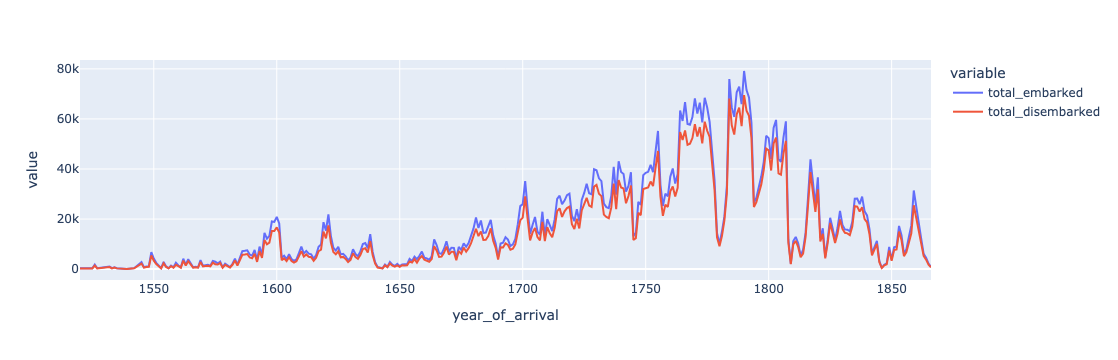

In [45]:
# Embarked vs. disembarked per year across the whole dataset
import plotly.express as px

yearly = voyages.groupby('year_of_arrival')[['total_embarked', 'total_disembarked']].sum().reset_index()
px.line(yearly, x='year_of_arrival', y=['total_embarked', 'total_disembarked'])

In [46]:
# Top 10 flags by people embarked
voyages.groupby('flag')['total_embarked'].sum().sort_values(ascending=False).head(10)

flag
Great Britain        2854511.0
France               1101843.0
Netherlands           508651.0
Spain / Uruguay       495096.0
Unknown               448376.0
Portugal / Brazil     368746.0
U.S.A.                253312.0
Denmark / Baltic       81334.0
Other                   2165.0
Name: total_embarked, dtype: float64

In [47]:
# Top 10 places of landing by people embarked
voyages.groupby('place_of_landing')['total_embarked'].sum().sort_values(ascending=False).head(10)

place_of_landing
Kingston                        512357.0
Jamaica, port unspecified       497802.0
Barbados, port unspecified      454539.0
Cap Francais                    397507.0
Havana                          366970.0
Cartagena                       255430.0
Suriname                        250738.0
Cuba, port unspecified          229852.0
Martinique, port unspecified    204362.0
Charleston                      174793.0
Name: total_embarked, dtype: float64

### 📝 My notes
- The line chart looks very clean. The lists are also looking clean and reveal important infomation. 

## Build the app (layout + callbacks)

In [53]:
import os
import pandas as pd
import dash
from dash import dcc
from dash import html
from dash.dependencies import Input, Output
import dash_bootstrap_components as dbc
import plotly.express as px

min_year = int(voyages['year_of_arrival'].min())
max_year = int(voyages['year_of_arrival'].max())

# dropdown options for the pie charts: column name -> label
pie_options = {
    'flag': 'Flag of vessel',
    'place_of_purchase': 'Place of purchase (Africa)',
    'place_of_landing': 'Place of landing (Americas)',
    'demographics': 'Women / children / men',
    'resistance_label': 'Resistance',
}

In [54]:
# App instance
app = dash.Dash(__name__, external_stylesheets=[dbc.themes.LITERA])
server = app.server

In [55]:
# Frontend: title, year slider, line chart, then two pie charts with dropdowns
def pie_column(dropdown_id, graph_id, default):
    return dbc.Col([
        dbc.Label("Show the make-up by:", className="fw-bold"),
        dcc.Dropdown(id=dropdown_id,
                     options=[{'label': label, 'value': col} for col, label in pie_options.items()],
                     value=default, clearable=False),
        dcc.Graph(id=graph_id)
    ], xs=12, md=6)

app.layout = dbc.Container(
    [   dbc.Row([ # row 1: title and intro
        dbc.Col([html.H1('The Trans-Atlantic Slave Trade to the Americas, 1520–1866'),
                 html.P('Captives embarked in Africa and disembarked in the Americas, by year of arrival. '
                        'Each record is a slaving voyage; behind every number are enslaved people.')],
        className="text-center mt-3 mb-3")
    ]),
        dbc.Row([ # row 2: year range selector (filters every chart)
            dbc.Label("Select a range of years:", className="fw-bold"),
            dcc.RangeSlider(
                id='year-range',
                min=min_year, max=max_year, step=1,
                value=[min_year, max_year],
                marks={y: str(y) for y in [min_year] + list(range(1550, max_year, 50)) + [max_year]},
                tooltip={"placement": "bottom", "always_visible": True}
            )
    ], className="mb-3"),

        dbc.Row([ # row 3: line chart
            dbc.Col(dcc.Graph(id='line-graph'))
    ]),

        dbc.Row([ # row 4: two pie charts with their own dropdowns
            pie_column('pie-left-var', 'pie-left', 'flag'),
            pie_column('pie-right-var', 'pie-right', 'place_of_landing')
    ]),

        dbc.Row([ # row 5: source
            dbc.Col(html.P(['Source: Trans-Atlantic Slave Trade Database, ',
                            html.A('SlaveVoyages.org', href='https://www.slavevoyages.org/')],
                           className="text-muted small text-center mt-3"))
    ])
    ])

In [56]:
# Backend: chart functions, then the callback that redraws all three charts
def make_line(dff):
    yearly = dff.groupby('year_of_arrival')[['total_embarked', 'total_disembarked']].sum().reset_index()
    yearly = yearly.rename(columns={'total_embarked': 'Embarked', 'total_disembarked': 'Disembarked'})
    yearly = yearly.melt(id_vars='year_of_arrival', var_name='Series', value_name='People')
    fig = px.line(yearly, x='year_of_arrival', y='People', color='Series',
                  title='People embarked in Africa vs. disembarked in the Americas')
    fig.update_layout(xaxis_title='Year of arrival', yaxis_title='Number of people')
    return fig

def short_label(name, max_len=20):
    # shorten long place names so the legend doesn't crowd the chart
    name = name.replace(', port unspecified', ' ')
    return name if len(name) <= max_len else name[:max_len - 1] + '…'

def make_pie(dff, variable):
    label = pie_options[variable]
    if variable == 'demographics':
        # only some voyages recorded the make-up of captives; estimate people from those
        known = dff.dropna(subset=['percent_women', 'percent_children', 'percent_men'])
        df_pie = pd.DataFrame({
            'Group': ['Women', 'Children', 'Men'],
            'People': [(known['percent_women'] * known['total_embarked']).sum(),
                       (known['percent_children'] * known['total_embarked']).sum(),
                       (known['percent_men'] * known['total_embarked']).sum()]
        })
        title = f"{label} (from {len(known):,} voyages with records)"
        names, values = 'Group', 'People'
    elif variable == 'resistance_label':
        # count voyages, only where resistance was recorded
        df_pie = dff['resistance_label'].value_counts().reset_index()
        df_pie.columns = ['Resistance', 'Voyages']
        title = f"{label} (voyages with resistance recorded: {df_pie['Voyages'].sum():,})"
        names, values = 'Resistance', 'Voyages'
    else:
        # share of people embarked; top 10 plus "Others"
        totals = dff.groupby(variable)['total_embarked'].sum().sort_values(ascending=False)
        df_pie = totals.head(10).reset_index()
        df_pie.columns = [label, 'People embarked']
        if len(totals) > 10:
            df_pie.loc[len(df_pie)] = ['Others', totals.iloc[10:].sum()]
        title = f"{label} (share of people embarked)"
        names, values = label, 'People embarked'

    if df_pie[values].sum() == 0:
        fig = px.pie(title=f"{label}: no records in these years")
        return fig
     # short names in the legend; the full name still shows on hover
    df_pie['Full name'] = df_pie[names]
    df_pie[names] = df_pie[names].map(short_label)
    fig = px.pie(df_pie, values=values, names=names, hole=.6, title=title,
                 hover_name='Full name',
                 color_discrete_sequence=px.colors.sequential.RdBu)
    # legend underneath the chart instead of beside it
    return fig

# callback decorator
@app.callback(
    Output('line-graph', 'figure'),
    Output('pie-left', 'figure'),
    Output('pie-right', 'figure'),
    Input('year-range', 'value'),
    Input('pie-left-var', 'value'),
    Input('pie-right-var', 'value')
)

# callback function
def update_output(year_range, left_var, right_var):
    # filter voyages to the selected years
    start_year, end_year = year_range
    mask = (voyages['year_of_arrival'] >= start_year) & (voyages['year_of_arrival'] <= end_year)
    dff = voyages.loc[mask]

    return make_line(dff), make_pie(dff, left_var), make_pie(dff, right_var)

### 📝 My notes
- Structure merges the two practices that I went through in Programming Historian. I wanted this to have an overarching line graph to show the number of people being sent. I also wanted to be able to have pie charts that provide more context to the numbers, signaling where people are from and where they are going. 

## Test

In [57]:
# port 8052 so it does not clash with notebooks 03 and 05
app.run(jupyter_mode="inline", debug=True, port=8052)

### 📝 My notes
- Initially, the pie charts are getting mushed together by the labels. You can't really see the pie chart when you select place of purchase for example. I will change this to list out the top 5
- Update. Played around with how much or the label is shown, which turned out to be the real problem. This allowed me to fit all 10 in and not have to worry about the chart being smushed. 

## Export to `app.py`
Writes the standalone app Render runs (Root Directory `my_dashboard`, Start Command `gunicorn app:server`). It reads `voyages.csv`, so run the cleaning cell first.

In [58]:
%%writefile ../my_dashboard/app.py
# My dashboard: the trans-Atlantic slave trade to the Americas, 1520–1866
# (exported from notebook 06). Run locally with:  python app.py   — on Render: gunicorn app:server

import os
import pandas as pd
import dash
from dash import dcc
from dash import html
from dash.dependencies import Input, Output
import dash_bootstrap_components as dbc
import plotly.express as px

# --- Data (cleaned in notebook 06) ---
csv_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), "voyages.csv")
voyages = pd.read_csv(csv_path)

min_year = int(voyages['year_of_arrival'].min())
max_year = int(voyages['year_of_arrival'].max())

# dropdown options for the pie charts: column name -> label
pie_options = {
    'flag': 'Flag of vessel',
    'place_of_purchase': 'Place of purchase (Africa)',
    'place_of_landing': 'Place of landing (Americas)',
    'demographics': 'Women / children / men',
    'resistance_label': 'Resistance',
}

# --- App instance ---
app = dash.Dash(__name__, external_stylesheets=[dbc.themes.LITERA])
server = app.server

# --- Frontend ---
def pie_column(dropdown_id, graph_id, default):
    return dbc.Col([
        dbc.Label("Show the make-up by:", className="fw-bold"),
        dcc.Dropdown(id=dropdown_id,
                     options=[{'label': label, 'value': col} for col, label in pie_options.items()],
                     value=default, clearable=False),
        dcc.Graph(id=graph_id)
    ], xs=12, md=6)

app.layout = dbc.Container(
    [   dbc.Row([ # row 1: title and intro
        dbc.Col([html.H1('The Trans-Atlantic Slave Trade to the Americas, 1520–1866'),
                 html.P('Captives embarked in Africa and disembarked in the Americas, by year of arrival. '
                        'Each record is a slaving voyage; behind every number are enslaved people.')],
        className="text-center mt-3 mb-3")
    ]),
        dbc.Row([ # row 2: year range selector (filters every chart)
            dbc.Label("Select a range of years:", className="fw-bold"),
            dcc.RangeSlider(
                id='year-range',
                min=min_year, max=max_year, step=1,
                value=[min_year, max_year],
                marks={y: str(y) for y in [min_year] + list(range(1550, max_year, 50)) + [max_year]},
                tooltip={"placement": "bottom", "always_visible": True}
            )
    ], className="mb-3"),

        dbc.Row([ # row 3: line chart
            dbc.Col(dcc.Graph(id='line-graph'))
    ]),

        dbc.Row([ # row 4: two pie charts with their own dropdowns
            pie_column('pie-left-var', 'pie-left', 'flag'),
            pie_column('pie-right-var', 'pie-right', 'place_of_landing')
    ]),

        dbc.Row([ # row 5: source
            dbc.Col(html.P(['Source: Trans-Atlantic Slave Trade Database, ',
                            html.A('SlaveVoyages.org', href='https://www.slavevoyages.org/')],
                           className="text-muted small text-center mt-3"))
    ])
    ])

# --- Backend ---
# Backend: chart functions, then the callback that redraws all three charts
def make_line(dff):
    yearly = dff.groupby('year_of_arrival')[['total_embarked', 'total_disembarked']].sum().reset_index()
    yearly = yearly.rename(columns={'total_embarked': 'Embarked', 'total_disembarked': 'Disembarked'})
    yearly = yearly.melt(id_vars='year_of_arrival', var_name='Series', value_name='People')
    fig = px.line(yearly, x='year_of_arrival', y='People', color='Series',
                  title='People embarked in Africa vs. disembarked in the Americas')
    fig.update_layout(xaxis_title='Year of arrival', yaxis_title='Number of people')
    return fig

def short_label(name, max_len=20):
    # shorten long place names so the legend doesn't crowd the chart
    name = name.replace(', port unspecified', ' ')
    return name if len(name) <= max_len else name[:max_len - 1] + '…'

def make_pie(dff, variable):
    label = pie_options[variable]
    if variable == 'demographics':
        # only some voyages recorded the make-up of captives; estimate people from those
        known = dff.dropna(subset=['percent_women', 'percent_children', 'percent_men'])
        df_pie = pd.DataFrame({
            'Group': ['Women', 'Children', 'Men'],
            'People': [(known['percent_women'] * known['total_embarked']).sum(),
                       (known['percent_children'] * known['total_embarked']).sum(),
                       (known['percent_men'] * known['total_embarked']).sum()]
        })
        title = f"{label} (from {len(known):,} voyages with records)"
        names, values = 'Group', 'People'
    elif variable == 'resistance_label':
        # count voyages, only where resistance was recorded
        df_pie = dff['resistance_label'].value_counts().reset_index()
        df_pie.columns = ['Resistance', 'Voyages']
        title = f"{label} (voyages with resistance recorded: {df_pie['Voyages'].sum():,})"
        names, values = 'Resistance', 'Voyages'
    else:
        # share of people embarked; top 10 plus "Others"
        totals = dff.groupby(variable)['total_embarked'].sum().sort_values(ascending=False)
        df_pie = totals.head(10).reset_index()
        df_pie.columns = [label, 'People embarked']
        if len(totals) > 10:
            df_pie.loc[len(df_pie)] = ['Others', totals.iloc[10:].sum()]
        title = f"{label} (share of people embarked)"
        names, values = label, 'People embarked'

    if df_pie[values].sum() == 0:
        fig = px.pie(title=f"{label}: no records in these years")
        return fig
     # short names in the legend; the full name still shows on hover
    df_pie['Full name'] = df_pie[names]
    df_pie[names] = df_pie[names].map(short_label)
    fig = px.pie(df_pie, values=values, names=names, hole=.6, title=title,
                 hover_name='Full name',
                 color_discrete_sequence=px.colors.sequential.RdBu)
    # legend underneath the chart instead of beside it
    return fig

# callback decorator
@app.callback(
    Output('line-graph', 'figure'),
    Output('pie-left', 'figure'),
    Output('pie-right', 'figure'),
    Input('year-range', 'value'),
    Input('pie-left-var', 'value'),
    Input('pie-right-var', 'value')
)

# callback function
def update_output(year_range, left_var, right_var):
    # filter voyages to the selected years
    start_year, end_year = year_range
    mask = (voyages['year_of_arrival'] >= start_year) & (voyages['year_of_arrival'] <= end_year)
    dff = voyages.loc[mask]

    return make_line(dff), make_pie(dff, left_var), make_pie(dff, right_var)

# callback decorator
@app.callback(
    Output('line-graph', 'figure'),
    Output('pie-left', 'figure'),
    Output('pie-right', 'figure'),
    Input('year-range', 'value'),
    Input('pie-left-var', 'value'),
    Input('pie-right-var', 'value')
)

# callback function
def update_output(year_range, left_var, right_var):
    # filter voyages to the selected years
    start_year, end_year = year_range
    mask = (voyages['year_of_arrival'] >= start_year) & (voyages['year_of_arrival'] <= end_year)
    dff = voyages.loc[mask]

    return make_line(dff), make_pie(dff, left_var), make_pie(dff, right_var)

if __name__ == '__main__':
    app.run(debug=True)

Overwriting ../my_dashboard/app.py


## ⚠️ Problems & fixes
| Problem / error | What fixed it |
|---|---|
| Pie chart sizing/labels being too long | decreasing length of label |